In [ ]:
QUICK_TEST = False        # True = tiny 300-step check of the whole notebook

import os, re, json, time, glob, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 0                  # seed for the data split and the Day 1 smoke test
P = 97                    # modulus (prime)
TRAIN_FRAC = 0.3          # share of all pairs used for training
HIDDEN = 256              # default width of the hidden layer
MAX_STEPS = 40000         # default step budget per run
STOP_AFTER_GROK = 1000    # extra steps to train after test accuracy hits THRESH
THRESH = 0.99
SEEDS = [0, 1, 2]

STEP_CAP = 300 if QUICK_TEST else None                # QUICK_TEST shortens every run
OUT_DIR = "results_quick" if QUICK_TEST else "results"   
RUN_DIR = f"{OUT_DIR}/runs"
os.makedirs(RUN_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| quick test:", QUICK_TEST, "| output folder:", OUT_DIR)
if device == "cpu" and not QUICK_TEST:
    print("WARNING: no GPU found. Real runs will be slow. Use Runtime > Change runtime type > T4 GPU.")

device: cuda | quick test: False | output folder: results


In [2]:
pairs = [(a, b) for a in range(P) for b in range(P)]
labels = [(a + b) % P for a, b in pairs]
print("total examples:", len(pairs))                  # 97 * 97 = 9409

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(pairs))                    # one fixed shuffle, reused everywhere
n_train = int(TRAIN_FRAC * len(pairs))
print("train:", n_train, "| test:", len(pairs) - n_train)

total examples: 9409
train: 2822 | test: 6587


In [3]:
def encode(ids):
    a = torch.tensor([pairs[i][0] for i in ids])
    b = torch.tensor([pairs[i][1] for i in ids])
    x = torch.cat([F.one_hot(a, P), F.one_hot(b, P)], dim=1).float()   # shape: (n, 194)
    y = torch.tensor([labels[i] for i in ids])
    return x.to(device), y.to(device)

DATA = {}
def get_data(frac):
    """(x_train, y_train, x_test, y_test) for a given training fraction, cached."""
    key = round(frac, 4)
    if key not in DATA:
        n = int(frac * len(pairs))
        DATA[key] = (*encode(perm[:n]), *encode(perm[n:]))
    return DATA[key]

x_train, y_train, x_test, y_test = get_data(TRAIN_FRAC)
print("x_train:", tuple(x_train.shape), "| x_test:", tuple(x_test.shape))

x_train: (2822, 194) | x_test: (6587, 194)


In [ ]:
def make_model(hidden=HIDDEN, seed=SEED):
    torch.manual_seed(seed)                      # same seed -> same starting weights
    return nn.Sequential(
        nn.Linear(2 * P, hidden), nn.ReLU(), nn.Linear(hidden, P)
    ).to(device)

def make_optimizer(model, name, lr, weight_decay):
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(f"unknown optimizer: {name}")

print("parameters:", sum(p.numel() for p in make_model().parameters()))   

parameters: 74849


In [5]:
@torch.no_grad()
def evaluate(model, x, y):
    logits = model(x)
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc

def train_simple(optimizer_name="adamw", lr=1e-3, weight_decay=1.0, steps=2000, log_every=100):
    model = make_model()
    opt = make_optimizer(model, optimizer_name, lr, weight_decay)
    h = {"step": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for step in range(steps + 1):
        if step % log_every == 0:
            tr_loss, tr_acc = evaluate(model, x_train, y_train)
            te_loss, te_acc = evaluate(model, x_test, y_test)
            for k, v in zip(h, [step, tr_loss, te_loss, tr_acc, te_acc]):
                h[k].append(v)
            if step % (5 * log_every) == 0:
                print(f"step {step:6d} | train acc {tr_acc:.3f} | test acc {te_acc:.3f} | "
                      f"train loss {tr_loss:.3f} | test loss {te_loss:.3f}")
        if step == steps:
            break
        loss = F.cross_entropy(model(x_train), y_train)   # 1. how wrong is the network?
        opt.zero_grad()                                   # 2. clear old gradients
        loss.backward()                                   # 3. how should each weight change?
        opt.step()                                        # 4. change the weights
    return h

smoke = train_simple()

step      0 | train acc 0.008 | test acc 0.013 | train loss 4.575 | test loss 4.576
step    500 | train acc 1.000 | test acc 0.000 | train loss 0.317 | test loss 9.159
step   1000 | train acc 1.000 | test acc 0.000 | train loss 0.126 | test loss 9.080
step   1500 | train acc 1.000 | test acc 0.000 | train loss 0.082 | test loss 8.673
step   2000 | train acc 1.000 | test acc 0.000 | train loss 0.058 | test loss 8.200


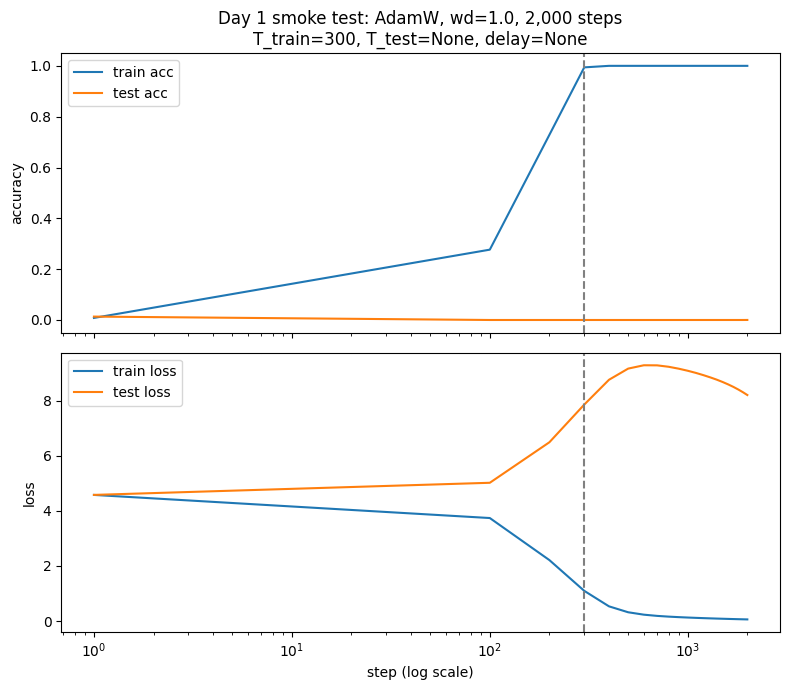

(300, None, None)

In [6]:
def first_step(h, key, thresh=THRESH):
    for s, v in zip(h["step"], h[key]):
        if v >= thresh:
            return s
    return None                          # never reached the threshold

def measure(h):
    t_train, t_test = first_step(h, "train_acc"), first_step(h, "test_acc")
    delay = (t_test - t_train) if (t_train is not None and t_test is not None) else None
    return t_train, t_test, delay

def plot_history(h, title, save_path=None):
    t_train, t_test, delay = measure(h)
    xs = [max(s, 1) for s in h["step"]]             # avoid log(0)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    ax1.plot(xs, h["train_acc"], label="train acc")
    ax1.plot(xs, h["test_acc"], label="test acc")
    ax2.plot(xs, h["train_loss"], label="train loss")
    ax2.plot(xs, h["test_loss"], label="test loss")
    for ax in (ax1, ax2):
        if t_train: ax.axvline(max(t_train, 1), ls="--", c="gray")
        if t_test:  ax.axvline(t_test, ls="--", c="red")
    ax1.set_xscale("log")
    ax1.set_ylabel("accuracy"); ax2.set_ylabel("loss"); ax2.set_xlabel("step (log scale)")
    extra = f"\nT_train={t_train}, T_test={t_test}, delay={delay}"
    ax1.set_title(title + extra)
    ax1.legend(); ax2.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()
    return t_train, t_test, delay

plot_history(smoke, "Day 1 smoke test: AdamW, wd=1.0, 2,000 steps", f"{OUT_DIR}/day1_smoke_test.png")

In [7]:
def should_log(step):
    # every 10 steps early (memorization is fast), every 100 later
    return step % 10 == 0 if step < 1000 else step % 100 == 0

def safe_name(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")

def run_path(name, seed):
    return f"{RUN_DIR}/{safe_name(name)}_seed{seed}.json"

def run_one(name, cfg, seed):
    """Train one (setting, seed). Saved to its own JSON file; finished runs are skipped."""
    path = run_path(name, seed)
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)

    frac = cfg.get("train_frac", TRAIN_FRAC)
    hid = cfg.get("hidden", HIDDEN)
    max_steps = cfg.get("max_steps", MAX_STEPS)
    if STEP_CAP:
        max_steps = min(max_steps, STEP_CAP)
    xtr, ytr, xte, yte = get_data(frac)

    model = make_model(hid, seed)
    opt = make_optimizer(model, cfg["optimizer"], cfg["lr"], cfg["weight_decay"])
    h = {"step": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    grok_step, diverged, start = None, False, time.time()

    for step in range(max_steps + 1):
        if should_log(step):
            tr_loss, tr_acc = evaluate(model, xtr, ytr)
            te_loss, te_acc = evaluate(model, xte, yte)
            for k, v in zip(h, [step, tr_loss, te_loss, tr_acc, te_acc]):
                h[k].append(v)
            if not np.isfinite(tr_loss):
                diverged = True
                break
            if grok_step is None and te_acc >= THRESH:
                grok_step = step
            if grok_step is not None and step >= grok_step + STOP_AFTER_GROK:
                break
        if step == max_steps:
            break
        loss = F.cross_entropy(model(xtr), ytr)
        opt.zero_grad()
        loss.backward()
        opt.step()

    t_train, t_test, delay = measure(h)
    result = {
        "name": name, "seed": seed,
        "config": {**cfg, "train_frac": frac, "hidden": hid, "max_steps": max_steps},
        "history": h, "T_train": t_train, "T_test": t_test, "delay": delay,
        "final_train_acc": h["train_acc"][-1], "final_test_acc": h["test_acc"][-1],
        "steps_run": h["step"][-1], "diverged": diverged,
        "seconds": round(time.time() - start, 1),
    }
    with open(path, "w") as f:
        json.dump(result, f)
    return result

def run_experiments(experiments, seeds=SEEDS):
    for name, cfg in experiments.items():
        for seed in seeds:
            existed = os.path.exists(run_path(name, seed))
            r = run_one(name, cfg, seed)
            tag = "(cached)" if existed else f"({r['seconds']}s)"
            print(f"{name:34s} seed {seed} | T_train={r['T_train']} T_test={r['T_test']} "
                  f"delay={r['delay']} | final test acc {r['final_test_acc']:.3f} | "
                  f"steps {r['steps_run']} {tag}")

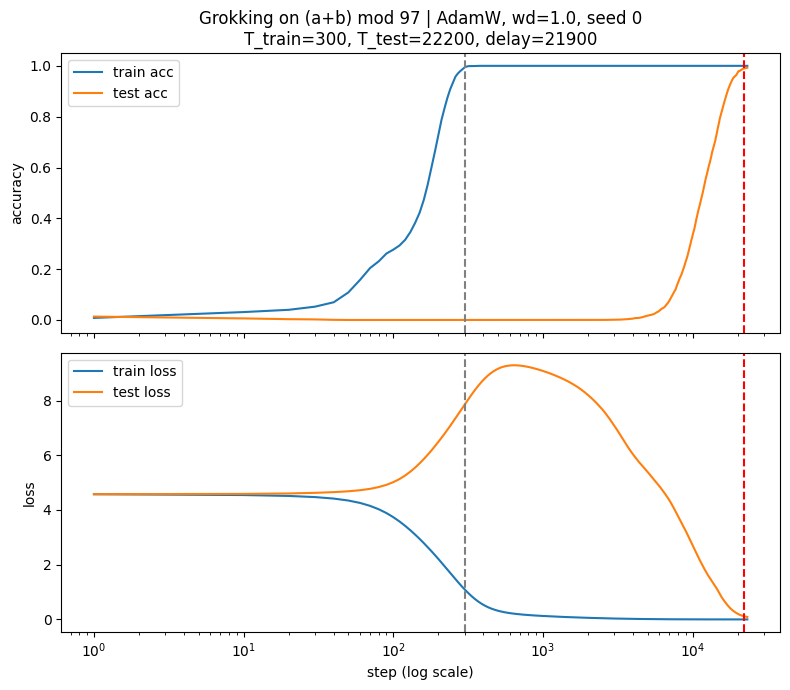

(300, 22200, 21900)

In [8]:
BASELINE = dict(optimizer="adamw", lr=1e-3, weight_decay=1.0)
base = run_one("AdamW (wd=1.0)", BASELINE, seed=0)
plot_history(base["history"], "Grokking on (a+b) mod 97 | AdamW, wd=1.0, seed 0",
             f"{OUT_DIR}/day2_baseline_adamw.png")

In [9]:
EXPERIMENTS = {
    "AdamW (wd=1.0)":              dict(optimizer="adamw", lr=1e-3, weight_decay=1.0),
    "AdamW (wd=2.0)":              dict(optimizer="adamw", lr=1e-3, weight_decay=2.0),
    "AdamW (wd=2.0, hidden=512)":  dict(optimizer="adamw", lr=1e-3, weight_decay=2.0, hidden=512),
    "Adam (wd=0)":                 dict(optimizer="adam",  lr=1e-3, weight_decay=0.0),
    "SGD+momentum (wd=0)":         dict(optimizer="sgd",   lr=0.1,  weight_decay=0.0),
    "SGD+momentum (wd=1e-3)":      dict(optimizer="sgd",   lr=0.1,  weight_decay=1e-3),
    "SGD+momentum (wd=0.002)":     dict(optimizer="sgd",   lr=0.1,  weight_decay=0.002),
    "SGD+momentum (wd=0.02)":      dict(optimizer="sgd",   lr=0.1,  weight_decay=0.02),
}
ORDER = list(EXPERIMENTS)          # keeps tables and plots in the order we defined the experiments
print(len(EXPERIMENTS), "settings x", len(SEEDS), "seeds =", len(EXPERIMENTS) * len(SEEDS), "runs")

8 settings x 3 seeds = 24 runs


In [10]:
run_experiments(EXPERIMENTS)

AdamW (wd=1.0)                     seed 0 | T_train=300 T_test=22200 delay=21900 | final test acc 0.993 | steps 23200 (cached)
AdamW (wd=1.0)                     seed 1 | T_train=290 T_test=21600 delay=21310 | final test acc 0.995 | steps 22600 (27.2s)
AdamW (wd=1.0)                     seed 2 | T_train=300 T_test=20600 delay=20300 | final test acc 0.993 | steps 21600 (26.3s)
AdamW (wd=2.0)                     seed 0 | T_train=340 T_test=19000 delay=18660 | final test acc 0.994 | steps 20000 (24.3s)
AdamW (wd=2.0)                     seed 1 | T_train=340 T_test=19300 delay=18960 | final test acc 0.992 | steps 20300 (24.7s)
AdamW (wd=2.0)                     seed 2 | T_train=330 T_test=20200 delay=19870 | final test acc 0.993 | steps 21200 (25.8s)
AdamW (wd=2.0, hidden=512)         seed 0 | T_train=190 T_test=11800 delay=11610 | final test acc 0.995 | steps 12800 (15.7s)
AdamW (wd=2.0, hidden=512)         seed 1 | T_train=190 T_test=11800 delay=11610 | final test acc 0.996 | steps 12800

In [11]:
def load_runs():
    rows = []
    for p in sorted(glob.glob(f"{RUN_DIR}/*.json")):
        with open(p) as f:
            r = json.load(f)
        c = r.get("config", {})
        rows.append(dict(
            name=r["name"], seed=r["seed"], optimizer=c.get("optimizer"),
            lr=c.get("lr"), weight_decay=c.get("weight_decay"),
            hidden=c.get("hidden", 256), train_frac=c.get("train_frac", 0.3),
            max_steps=c.get("max_steps", 40000),
            T_train=r.get("T_train"), T_test=r.get("T_test"), delay=r.get("delay"),
            final_train_acc=r.get("final_train_acc"), final_test_acc=r.get("final_test_acc"),
            steps_run=r.get("steps_run"), diverged=r.get("diverged")))
    df = pd.DataFrame(rows)
    for col in ["T_train", "T_test", "delay"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")      # None -> NaN
    return df

def summarise(df):
    out = []
    for name in sorted(df["name"].unique(), key=lambda n: ORDER.index(n) if n in ORDER else 999):
        g = df[df["name"] == name]
        ok = g.dropna(subset=["delay"])
        out.append({
            "experiment": name, "runs": len(g), "grokked_n": len(ok),
            "grokked": f"{len(ok)}/{len(g)}",
            "mean_delay": ok["delay"].mean() if len(ok) else np.nan,
            "std_delay": ok["delay"].std(ddof=1) if len(ok) > 1 else np.nan,
            "min_delay": ok["delay"].min() if len(ok) else np.nan,
            "max_delay": ok["delay"].max() if len(ok) else np.nan,
            "mean_T_train": g["T_train"].mean(),
            "mean_final_train_acc": g["final_train_acc"].mean(),
            "mean_final_test_acc": g["final_test_acc"].mean(),
            "budget": g["max_steps"].max(),
        })
    return pd.DataFrame(out)

runs_df = load_runs()
summary_df = summarise(runs_df)
runs_df.to_csv(f"{OUT_DIR}/all_runs.csv", index=False)
summary_df.to_csv(f"{OUT_DIR}/summary.csv", index=False)
print(summary_df.drop(columns=["grokked_n", "budget"]).round(3).to_string(index=False))

                experiment  runs grokked  mean_delay  std_delay  min_delay  max_delay  mean_T_train  mean_final_train_acc  mean_final_test_acc
            AdamW (wd=1.0)     3     3/3   21170.000    809.135    20300.0    21900.0       296.667                 1.000                0.993
            AdamW (wd=2.0)     3     3/3   19163.333    630.106    18660.0    19870.0       336.667                 1.000                0.993
AdamW (wd=2.0, hidden=512)     3     3/3   11610.000      0.000    11610.0    11610.0       190.000                 1.000                0.996
               Adam (wd=0)     3     0/3         NaN        NaN        NaN        NaN       270.000                 1.000                0.000
       SGD+momentum (wd=0)     3     0/3         NaN        NaN        NaN        NaN      2400.000                 1.000                0.000
    SGD+momentum (wd=1e-3)     3     0/3         NaN        NaN        NaN        NaN      8366.667                 1.000                0.032

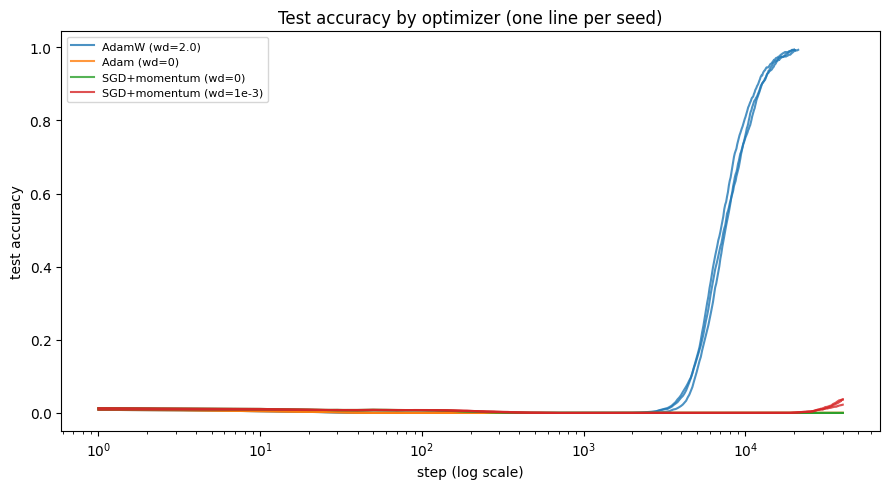

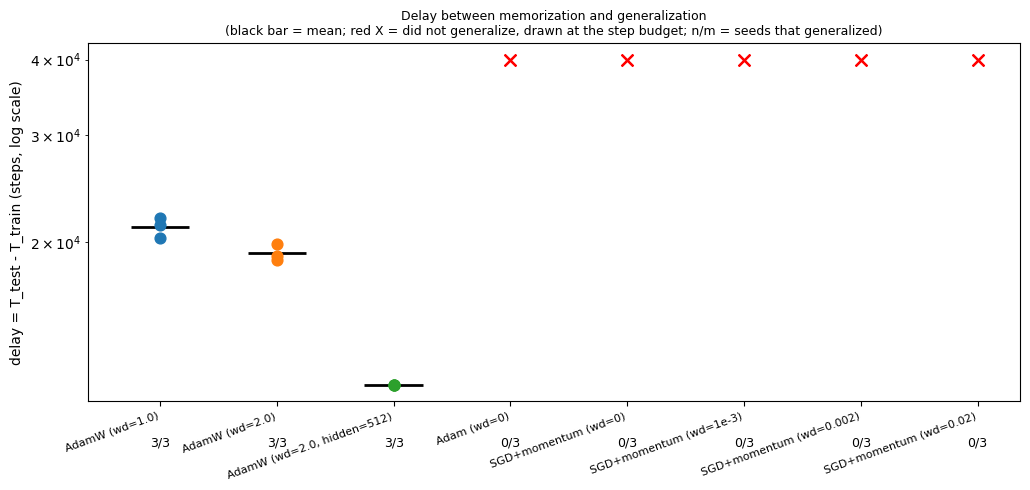

In [12]:
def existing(names):
    return [n for n in names if any(os.path.exists(run_path(n, s)) for s in SEEDS)]

def plot_overlay(names, title, fname):
    names = existing(names)
    if not names:
        print("nothing to plot yet:", title); return
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    plt.figure(figsize=(9, 5))
    for i, name in enumerate(names):
        first = True
        for seed in SEEDS:
            if not os.path.exists(run_path(name, seed)):
                continue
            with open(run_path(name, seed)) as f:
                h = json.load(f)["history"]
            plt.plot([max(s, 1) for s in h["step"]], h["test_acc"], color=colors[i % len(colors)],
                     alpha=0.8, lw=1.5, label=name if first else None)
            first = False
    plt.xscale("log"); plt.xlabel("step (log scale)"); plt.ylabel("test accuracy")
    plt.title(title + " (one line per seed)")
    plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

def plot_delays(df, names, title, fname):
    names = [n for n in names if n in set(df["name"])]
    if not names:
        print("nothing to plot yet:", title); return
    plt.figure(figsize=(max(7, 1.3 * len(names)), 5))
    for i, name in enumerate(names):
        g = df[df["name"] == name]
        ok, bad = g.dropna(subset=["delay"]), g[g["delay"].isna()]
        plt.scatter([i] * len(ok), ok["delay"], s=60, zorder=3)
        if len(ok):
            plt.hlines(ok["delay"].mean(), i - 0.25, i + 0.25, colors="k", lw=2)
        if len(bad):
            plt.scatter([i] * len(bad), bad["max_steps"], marker="x", c="red", s=70, zorder=3)
        plt.text(i, -0.1, f"{len(ok)}/{len(g)}", ha="center", va="top",
                 transform=plt.gca().get_xaxis_transform(), fontsize=9)
    plt.xticks(range(len(names)), names, rotation=20, ha="right", fontsize=8)
    plt.yscale("log"); plt.ylabel("delay = T_test - T_train (steps, log scale)")
    plt.title(title + "\n(black bar = mean; red X = did not generalize, drawn at the step budget; n/m = seeds that generalized)", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

MAIN = ["AdamW (wd=2.0)", "Adam (wd=0)", "SGD+momentum (wd=0)", "SGD+momentum (wd=1e-3)"]
plot_overlay(MAIN, "Test accuracy by optimizer", "overlay_main.png")
plot_delays(runs_df, list(EXPERIMENTS), "Delay between memorization and generalization", "delay_day3.png")

In [13]:
SGD_LONG = {
    "SGD+momentum (wd=1e-3, 150k)": dict(optimizer="sgd", lr=0.1, weight_decay=1e-3, max_steps=150000),
    "SGD+momentum (wd=5e-4, 150k)": dict(optimizer="sgd", lr=0.1, weight_decay=5e-4, max_steps=150000),
    "SGD+momentum (wd=3e-4, 150k)": dict(optimizer="sgd", lr=0.1, weight_decay=3e-4, max_steps=150000),
}
ORDER += list(SGD_LONG)
run_experiments(SGD_LONG)

SGD+momentum (wd=1e-3, 150k)       seed 0 | T_train=8800 T_test=None delay=None | final test acc 0.172 | steps 150000 (160.2s)
SGD+momentum (wd=1e-3, 150k)       seed 1 | T_train=7900 T_test=None delay=None | final test acc 0.251 | steps 150000 (158.4s)
SGD+momentum (wd=1e-3, 150k)       seed 2 | T_train=8400 T_test=None delay=None | final test acc 0.218 | steps 150000 (158.4s)
SGD+momentum (wd=5e-4, 150k)       seed 0 | T_train=3900 T_test=None delay=None | final test acc 0.495 | steps 150000 (160.4s)
SGD+momentum (wd=5e-4, 150k)       seed 1 | T_train=3900 T_test=None delay=None | final test acc 0.430 | steps 150000 (159.8s)
SGD+momentum (wd=5e-4, 150k)       seed 2 | T_train=3900 T_test=None delay=None | final test acc 0.455 | steps 150000 (158.4s)
SGD+momentum (wd=3e-4, 150k)       seed 0 | T_train=3100 T_test=None delay=None | final test acc 0.499 | steps 150000 (158.7s)
SGD+momentum (wd=3e-4, 150k)       seed 1 | T_train=3100 T_test=None delay=None | final test acc 0.451 | steps 

                  experiment grokked  mean_delay  mean_T_train  mean_final_train_acc  mean_final_test_acc
              AdamW (wd=2.0)     3/3   19163.333       336.667                   1.0                0.993
SGD+momentum (wd=1e-3, 150k)     0/3         NaN      8366.667                   1.0                0.213
SGD+momentum (wd=5e-4, 150k)     0/3         NaN      3900.000                   1.0                0.460
SGD+momentum (wd=3e-4, 150k)     0/3         NaN      3100.000                   1.0                0.480


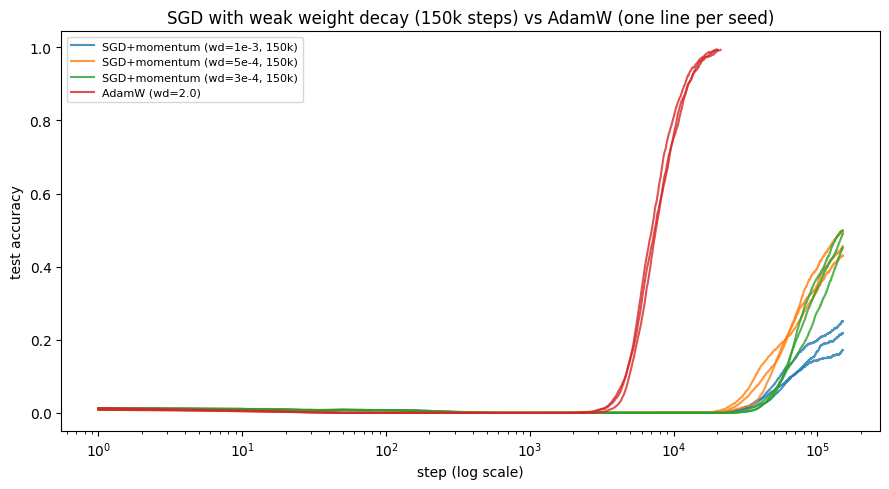

In [14]:
runs_df = load_runs(); summary_df = summarise(runs_df)
runs_df.to_csv(f"{OUT_DIR}/all_runs.csv", index=False)
summary_df.to_csv(f"{OUT_DIR}/summary.csv", index=False)

long_names = list(SGD_LONG) + ["AdamW (wd=2.0)"]
print(summary_df[summary_df["experiment"].isin(long_names)]
      [["experiment", "grokked", "mean_delay", "mean_T_train", "mean_final_train_acc", "mean_final_test_acc"]]
      .round(3).to_string(index=False))
plot_overlay(long_names, "SGD with weak weight decay (150k steps) vs AdamW", "overlay_sgd_long.png")

In [15]:
EXTRA_WD = {f"AdamW (wd={wd})": dict(optimizer="adamw", lr=1e-3, weight_decay=wd)
            for wd in [0.1, 0.5, 4.0]}
EXTRA_FRAC = {f"AdamW (wd=2.0, frac={fr})": dict(optimizer="adamw", lr=1e-3, weight_decay=2.0, train_frac=fr)
              for fr in [0.2, 0.4, 0.5]}

ORDER += list(EXTRA_WD) + list(EXTRA_FRAC)
run_experiments(EXTRA_WD)
run_experiments(EXTRA_FRAC)

AdamW (wd=0.1)                     seed 0 | T_train=270 T_test=None delay=None | final test acc 0.048 | steps 40000 (49.0s)
AdamW (wd=0.1)                     seed 1 | T_train=270 T_test=None delay=None | final test acc 0.047 | steps 40000 (49.5s)
AdamW (wd=0.1)                     seed 2 | T_train=270 T_test=None delay=None | final test acc 0.025 | steps 40000 (49.6s)
AdamW (wd=0.5)                     seed 0 | T_train=280 T_test=38700 delay=38420 | final test acc 0.991 | steps 39700 (49.1s)
AdamW (wd=0.5)                     seed 1 | T_train=280 T_test=None delay=None | final test acc 0.986 | steps 40000 (49.0s)
AdamW (wd=0.5)                     seed 2 | T_train=280 T_test=None delay=None | final test acc 0.986 | steps 40000 (49.3s)
AdamW (wd=4.0)                     seed 0 | T_train=560 T_test=None delay=None | final test acc 0.833 | steps 40000 (49.0s)
AdamW (wd=4.0)                     seed 1 | T_train=540 T_test=None delay=None | final test acc 0.842 | steps 40000 (48.7s)
AdamW 

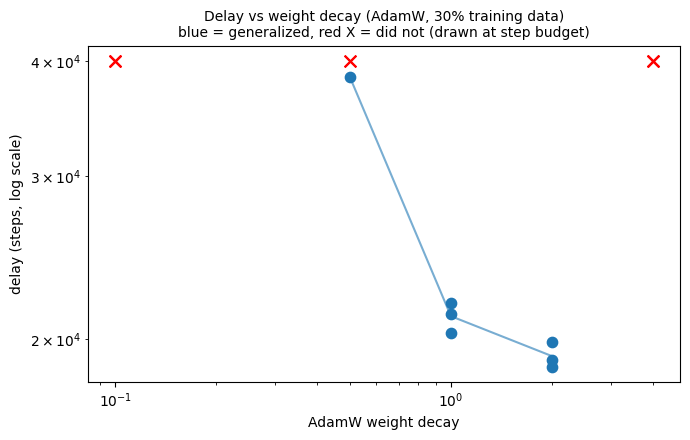

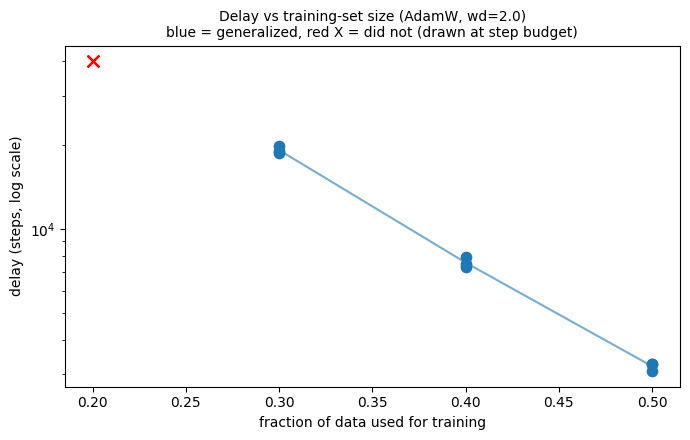

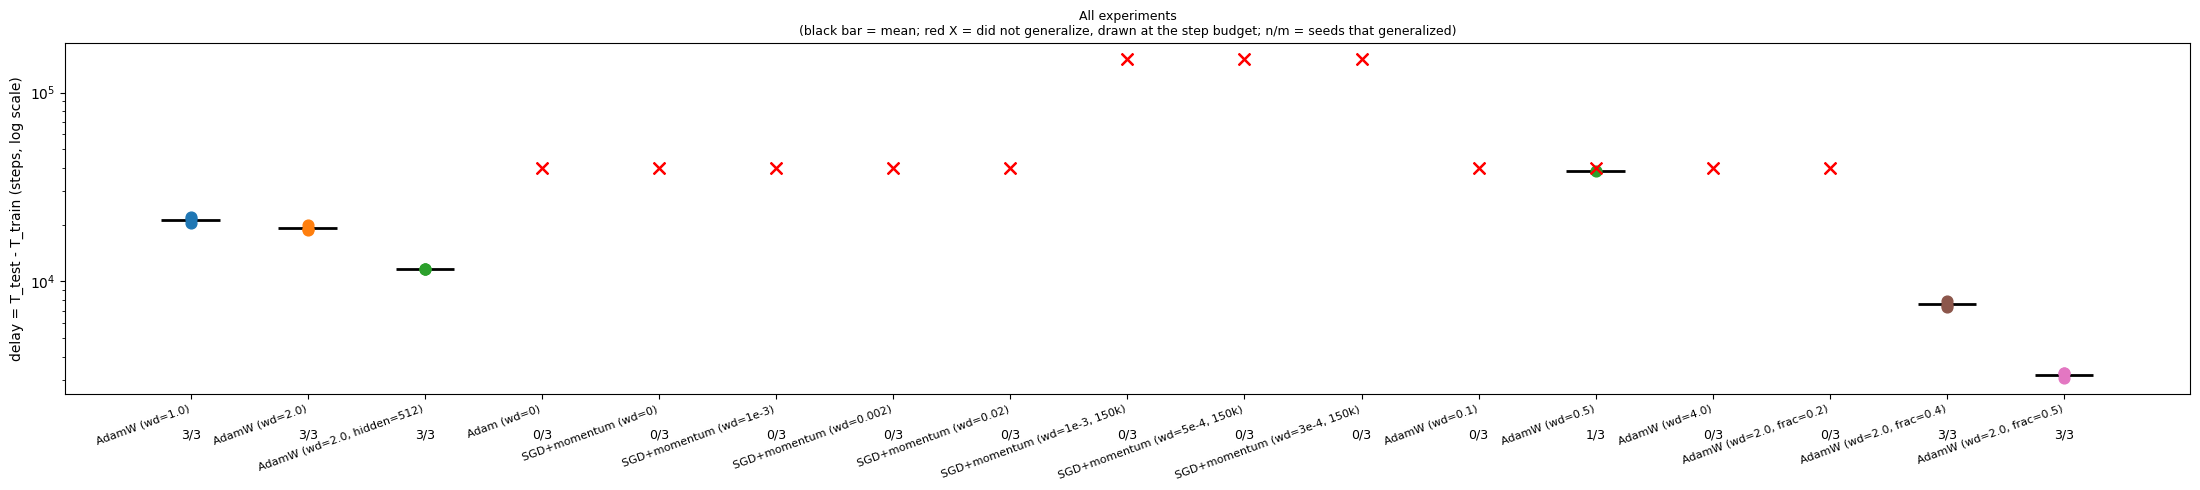

In [16]:
runs_df = load_runs(); summary_df = summarise(runs_df)
runs_df.to_csv(f"{OUT_DIR}/all_runs.csv", index=False)
summary_df.to_csv(f"{OUT_DIR}/summary.csv", index=False)

def plot_sweep(df, mask, xcol, xlabel, title, fname, logx=False):
    d = df[mask]
    if d.empty or d[xcol].nunique() < 2:
        print("not enough runs yet for:", title); return
    plt.figure(figsize=(7, 4.5))
    means = []
    for x in sorted(d[xcol].unique()):
        g = d[d[xcol] == x]
        ok, bad = g.dropna(subset=["delay"]), g[g["delay"].isna()]
        plt.scatter([x] * len(ok), ok["delay"], s=55, color="tab:blue", zorder=3)
        if len(bad):
            plt.scatter([x] * len(bad), bad["max_steps"], marker="x", color="red", s=70, zorder=3)
        if len(ok):
            means.append((x, ok["delay"].mean()))
    if means:
        plt.plot(*zip(*means), color="tab:blue", alpha=0.6)
    if logx: plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(xlabel); plt.ylabel("delay (steps, log scale)")
    plt.title(title + "\nblue = generalized, red X = did not (drawn at step budget)", fontsize=10)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

adamw_base = (runs_df.optimizer == "adamw") & ((runs_df.train_frac - 0.3).abs() < 1e-9) & (runs_df.hidden == 256)
plot_sweep(runs_df, adamw_base & (runs_df.weight_decay > 0), "weight_decay", "AdamW weight decay",
           "Delay vs weight decay (AdamW, 30% training data)", "sweep_weight_decay.png", logx=True)

adamw_wd2 = (runs_df.optimizer == "adamw") & (runs_df.weight_decay == 2.0) & (runs_df.hidden == 256)
plot_sweep(runs_df, adamw_wd2, "train_frac", "fraction of data used for training",
           "Delay vs training-set size (AdamW, wd=2.0)", "sweep_train_frac.png")

plot_delays(runs_df, list(summary_df["experiment"]), "All experiments", "delay_all.png")

In [17]:
def markdown_table(s):
    lines = ["| Experiment | Seeds that generalized | Delay in steps (mean +/- std; min-max) | Final test acc (mean) |",
             "|---|---|---|---|"]
    for _, r in s.iterrows():
        if r.grokked_n == 0:
            d = f"none within {int(r.budget):,} steps"
        elif r.grokked_n == 1:
            d = f"{r.mean_delay:,.0f}"
        else:
            d = f"{r.mean_delay:,.0f} +/- {r.std_delay:,.0f} ({r.min_delay:,.0f}-{r.max_delay:,.0f})"
        lines.append(f"| {r.experiment} | {r.grokked} | {d} | {r.mean_final_test_acc:.3f} |")
    return "\n".join(lines)

def print_claims(s):
    for _, r in s.iterrows():
        if r.grokked_n:
            rng_txt = f"{r.min_delay:,.0f}" if r.min_delay == r.max_delay else f"{r.min_delay:,.0f}-{r.max_delay:,.0f}"
            print(f"- {r.experiment}: {r.grokked} seeds generalized; delay {rng_txt} steps")
        else:
            print(f"- {r.experiment}: 0/{r.runs} generalized within {int(r.budget):,} steps "
                  f"(final train acc {r.mean_final_train_acc:.2f}, final test acc {r.mean_final_test_acc:.2f})")

print(markdown_table(summary_df))
print()
print_claims(summary_df)

| Experiment | Seeds that generalized | Delay in steps (mean +/- std; min-max) | Final test acc (mean) |
|---|---|---|---|
| AdamW (wd=1.0) | 3/3 | 21,170 +/- 809 (20,300-21,900) | 0.993 |
| AdamW (wd=2.0) | 3/3 | 19,163 +/- 630 (18,660-19,870) | 0.993 |
| AdamW (wd=2.0, hidden=512) | 3/3 | 11,610 +/- 0 (11,610-11,610) | 0.996 |
| Adam (wd=0) | 0/3 | none within 40,000 steps | 0.000 |
| SGD+momentum (wd=0) | 0/3 | none within 40,000 steps | 0.000 |
| SGD+momentum (wd=1e-3) | 0/3 | none within 40,000 steps | 0.032 |
| SGD+momentum (wd=0.002) | 0/3 | none within 40,000 steps | 0.000 |
| SGD+momentum (wd=0.02) | 0/3 | none within 40,000 steps | 0.009 |
| SGD+momentum (wd=1e-3, 150k) | 0/3 | none within 150,000 steps | 0.213 |
| SGD+momentum (wd=5e-4, 150k) | 0/3 | none within 150,000 steps | 0.460 |
| SGD+momentum (wd=3e-4, 150k) | 0/3 | none within 150,000 steps | 0.480 |
| AdamW (wd=0.1) | 0/3 | none within 40,000 steps | 0.040 |
| AdamW (wd=0.5) | 1/3 | 38,420 | 0.988 |
| AdamW (wd=4.0